# Power Plant and Protein Structure results

This notebook asks whether Gaussian-process methods have an advantage over neural-network methods in the small-data regime, whether that advantage changes as the training set grows, how the DKL hybrid behaves, and what predictive quality is exchanged for the computational savings of sparse GPs. It analyses 1,520 benchmark runs in three stages:

1. predictive accuracy using **RMSE only**;
2. uncertainty quality using **Gaussian NLL, Gaussian CRPS, and 90% interval coverage**;
3. computational cost using **final training time and full-test inference time**.

All summaries keep the two datasets separate. Error bars are 95% *t*-intervals over 20 repeated splits. Sparse-GP configurations appear only when the training size is strictly larger than their inducing-point count.

## Research framing and expectations

The comparison distinguishes four method types:

- **Exact GP:** `exact_gp`, the reference GP with no inducing-point approximation.
- **Sparse GPs:** `sparse_gp_m16`, `sparse_gp_m64`, and `sparse_gp_m256`. They are expected to reduce cost, particularly at larger training sizes, with a possible loss in predictive quality or calibration.
- **NN-based methods:** `deep_ensemble` and `mc_dropout`. The motivating expectation is that they struggle most when observations are scarce and become more competitive as data grows.
- **Hybrid:** `dkl`, which learns neural features but retains an exact GP prediction head.

These are hypotheses, not assumptions imposed on the interpretation. The key question is whether the observed learning curves support the expected crossover from GP to NN methods on both datasets.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import t
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

results_relative_path = Path("results/tables/power_plant_experiment.csv")
project_root = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / results_relative_path).exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError(f"Could not locate {results_relative_path}")

results_path = project_root / results_relative_path
results = pd.read_csv(results_path)
dataset_labels = {
    "combined_cycle_power_plant": "Power Plant",
    "protein_tertiary_structure": "Protein Structure",
}
datasets = list(dataset_labels)
model_order = [
    "exact_gp", "sparse_gp_m16", "sparse_gp_m64",
    "sparse_gp_m256", "deep_ensemble", "mc_dropout", "dkl",
]
model_order = [model for model in model_order if model in set(results["model"])]
nn_models = ["deep_ensemble", "mc_dropout"]
sparse_models = [model for model in model_order if model.startswith("sparse_gp_")]
palette = dict(zip(model_order, sns.color_palette("tab10", len(model_order))))
print(f"Loaded {len(results):,} rows from {results_path}")

Loaded 1,520 rows from /Users/paulbahde/Desktop/UncertaintyQuantification/results/tables/power_plant_experiment.csv


In [2]:
required_columns = {
    "dataset", "split", "train_size", "model", "n_inducing",
    "final_training_time_seconds", "inference_time_seconds",
    "rmse", "nll", "crps", "coverage_90",
}
missing = required_columns.difference(results.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
key_columns = ["dataset", "split", "train_size", "model"]
if results.duplicated(key_columns).any():
    raise ValueError("Duplicate dataset/split/train-size/model rows found")
if not np.isfinite(results[["rmse", "nll", "crps", "coverage_90"]]).all().all():
    raise ValueError("Non-finite evaluation metrics found")
if not results["coverage_90"].between(0, 1).all():
    raise ValueError("Coverage must lie between zero and one")
if not results.groupby("dataset")["split"].nunique().eq(20).all():
    raise ValueError("Expected 20 splits for each dataset")

results["coverage_error_90"] = (results["coverage_90"] - 0.90).abs()
group_columns = ["dataset", "train_size", "model"]
metrics = [
    "rmse", "nll", "crps", "coverage_90", "coverage_error_90",
    "final_training_time_seconds", "inference_time_seconds",
]

def aggregate_metric(frame, metric):
    summary = (frame.groupby(group_columns, observed=True)[metric]
               .agg(mean="mean", std="std", n="count").reset_index())
    summary["sem"] = summary["std"] / np.sqrt(summary["n"])
    summary["ci95"] = t.ppf(0.975, summary["n"] - 1) * summary["sem"]
    return summary

aggregated = pd.concat(
    [aggregate_metric(results, metric).assign(metric=metric) for metric in metrics],
    ignore_index=True,
)
means = results.groupby(group_columns, observed=True)[metrics].mean().reset_index()
availability = results.pivot_table(
    index=["dataset", "train_size"], columns="model",
    values="split", aggfunc="nunique", fill_value=0,
).reindex(columns=model_order)
availability.index = pd.MultiIndex.from_tuples(
    [(dataset_labels[dataset], size) for dataset, size in availability.index],
    names=["dataset", "train_size"],
)
display(availability)

model                         exact_gp  sparse_gp_m16  sparse_gp_m64  \
dataset           train_size                                           
Power Plant       50                20             20              0   
                  100               20             20             20   
                  200               20             20             20   
                  400               20             20             20   
                  800               20             20             20   
                  1600              20             20             20   
Protein Structure 50                20             20              0   
                  100               20             20             20   
                  200               20             20             20   
                  400               20             20             20   
                  800               20             20             20   
                  1600              20             20             20   

model                         sparse_gp_m256  deep_ensemble  mc_dropout  dkl  
dataset           train_size                                                  
Power Plant       50                       0             20          20   20  
                  100                      0             20          20   20  
                  200                      0             20          20   20  
                  400                     20             20          20   20  
                  800                     20             20          20   20  
                  1600                    20             20          20   20  
Protein Structure 50                       0             20          20   20  
                  100                      0             20          20   20  
                  200                      0             20          20   20  
                  400                     20             20          20   20  
                  800                     20             20          20   20  
                  1600                    20             20          20   20

# 1. Predictive accuracy — RMSE

This section compares point-prediction accuracy only. Lower RMSE is better. No uncertainty or runtime metric is mixed into this comparison.

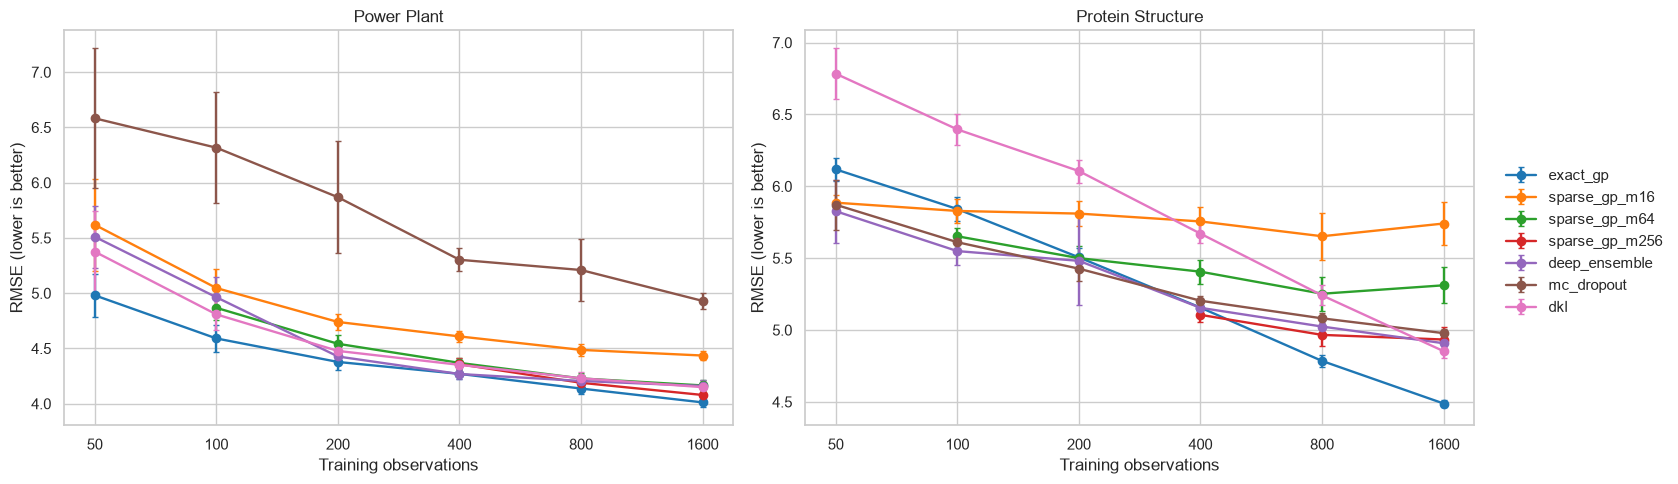

In [3]:
fig, axes = plt.subplots(1, len(datasets), figsize=(15, 5), sharey=False)
for ax, dataset in zip(axes, datasets):
    metric_data = aggregated[(aggregated["dataset"] == dataset) & (aggregated["metric"] == "rmse")]
    for model in model_order:
        group = metric_data[metric_data["model"] == model].sort_values("train_size")
        if not group.empty:
            ax.errorbar(group["train_size"], group["mean"], yerr=group["ci95"],
                        marker="o", capsize=2, linewidth=1.7, color=palette[model], label=model)
    ax.set_xscale("log", base=2)
    ax.set_xticks(sorted(results["train_size"].unique()))
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_title(dataset_labels[dataset])
    ax.set_xlabel("Training observations")
    ax.set_ylabel("RMSE (lower is better)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.tight_layout()
plt.show()

In [4]:
# Directly compare the exact GP, the best pure NN, DKL, and the best eligible sparse GP.
rmse_family_rows = []
for (dataset, train_size), current in means.groupby(["dataset", "train_size"]):
    indexed = current.set_index("model")
    exact = indexed.loc["exact_gp"]
    best_nn = current[current["model"].isin(nn_models)].sort_values("rmse").iloc[0]
    best_sparse = current[current["model"].isin(sparse_models)].sort_values("rmse").iloc[0]
    dkl = indexed.loc["dkl"]
    rmse_family_rows.append({
        "dataset": dataset_labels[dataset], "train_size": train_size,
        "exact_gp": exact["rmse"],
        "best_nn": best_nn["model"], "best_nn_rmse": best_nn["rmse"],
        "nn_gap_vs_exact_pct": 100 * (best_nn["rmse"] / exact["rmse"] - 1),
        "dkl_rmse": dkl["rmse"],
        "dkl_gap_vs_exact_pct": 100 * (dkl["rmse"] / exact["rmse"] - 1),
        "best_sparse": best_sparse["model"], "best_sparse_rmse": best_sparse["rmse"],
        "sparse_gap_vs_exact_pct": 100 * (best_sparse["rmse"] / exact["rmse"] - 1),
    })
rmse_family_comparison = pd.DataFrame(rmse_family_rows)
display(rmse_family_comparison)

largest_size = int(results["train_size"].max())
paired_rows = []
for dataset in datasets:
    current = results[(results["dataset"] == dataset) & (results["train_size"] == largest_size)]
    model_means = current.groupby("model")["rmse"].mean().sort_values()
    best, runner_up = model_means.index[:2]
    paired = current.pivot(index="split", columns="model", values="rmse")[[best, runner_up]].dropna()
    difference = paired[best] - paired[runner_up]
    half_width = t.ppf(0.975, len(difference) - 1) * difference.sem()
    paired_rows.append({
        "dataset": dataset_labels[dataset], "best": best, "runner_up": runner_up,
        "best_mean_rmse": model_means[best], "runner_up_mean_rmse": model_means[runner_up],
        "paired_difference": difference.mean(),
        "difference_ci_low": difference.mean() - half_width,
        "difference_ci_high": difference.mean() + half_width,
        "best_split_wins": int((difference < 0).sum()), "paired_splits": len(difference),
    })
print(f"Paired RMSE comparison at n={largest_size:,}")
display(pd.DataFrame(paired_rows))

,dataset,train_size,exact_gp,best_nn,best_nn_rmse,nn_gap_vs_exact_pct,dkl_rmse,dkl_gap_vs_exact_pct,best_sparse,best_sparse_rmse,sparse_gap_vs_exact_pct
0,Power Plant,50,4.9806,deep_ensemble,5.5100,10.6298,5.3755,7.9285,sparse_gp_m16,5.6187,12.8116
1,Power Plant,100,4.5905,deep_ensemble,4.9633,8.1203,4.8081,4.7403,sparse_gp_m64,4.8675,6.0340
2,Power Plant,200,4.3777,deep_ensemble,4.4270,1.1280,4.4776,2.2821,sparse_gp_m64,4.5419,3.7527
3,Power Plant,400,4.2699,deep_ensemble,4.2684,-0.0341,4.3515,1.9114,sparse_gp_m256,4.3572,2.0435
4,Power Plant,800,4.1370,deep_ensemble,4.2059,1.6654,4.2298,2.2446,sparse_gp_m256,4.1892,1.2622
5,Power Plant,1600,4.0117,deep_ensemble,4.1600,3.6972,4.1495,3.4363,sparse_gp_m256,4.0788,1.6725
6,Protein Structure,50,6.1178,deep_ensemble,5.8267,-4.7586,6.7836,10.8829,sparse_gp_m16,5.8862,-3.7868
7,Protein Structure,100,5.8417,deep_ensemble,5.5492,-5.0078,6.3960,9.4885,sparse_gp_m64,5.6524,-3.2407
8,Protein Structure,200,5.5056,mc_dropout,5.4269,-1.4301,6.1060,10.9051,sparse_gp_m64,5.5003,-0.0974
9,Protein Structure,400,5.1559,deep_ensemble,5.1545,-0.0277,5.6706,9.9818,sparse_gp_m256,5.1055,-0.9777


Paired RMSE comparison at n=1,600


,dataset,best,runner_up,best_mean_rmse,runner_up_mean_rmse,paired_difference,difference_ci_low,difference_ci_high,best_split_wins,paired_splits
0,Power Plant,exact_gp,sparse_gp_m256,4.0117,4.0788,-0.0671,-0.0783,-0.0559,20,20
1,Protein Structure,exact_gp,dkl,4.4885,4.8528,-0.3642,-0.4079,-0.3206,20,20


### RMSE findings in relation to the hypothesis

- **Power Plant supports the expected small-data GP advantage.** At `n=50`, the best NN (deep ensemble) has **10.6% higher RMSE** than exact GP; the gap narrows to **1.1%** by `n=200`. The deep ensemble only draws level at `n=400` (a negligible **0.03%** advantage), and exact GP leads again thereafter. Thus the NN improves with more data in absolute terms, but it does **not** overtake the exact GP consistently within the tested range.
- **Protein Structure contradicts a universal small-data GP advantage.** The best NN has **4.8%–5.0% lower RMSE** than exact GP at `n=50` and `n=100`, remains slightly better through `n=400`, and then loses at `n=800`. At `n=1,600`, exact GP is **9.3% better** than the best NN. The observed crossover is therefore the reverse of the motivating expectation: it favors the GP as data grows.
- **DKL does not provide a consistent hybrid advantage.** On Power Plant it sits between exact GP and the pure NNs at the smallest sizes, but never wins. On Protein Structure it is especially weak in the small-data regime (RMSE **10.9% above exact GP** at `n=50`) and remains **8.1% above exact GP** at `n=1,600`, despite improving strongly in absolute terms.
- At `n=1,600`, exact GP beats the RMSE runner-up in **all 20 paired splits** on both datasets, so its large-size lead is consistent across the sampled partitions rather than driven by a few splits.

# 2. Uncertainty measures — NLL, CRPS, and coverage

Gaussian NLL and Gaussian CRPS are proper scoring rules; lower is better. Empirical coverage should be close to the nominal 0.90 level. Coverage above 0.90 indicates conservative intervals, while coverage below 0.90 indicates undercoverage or overconfidence.

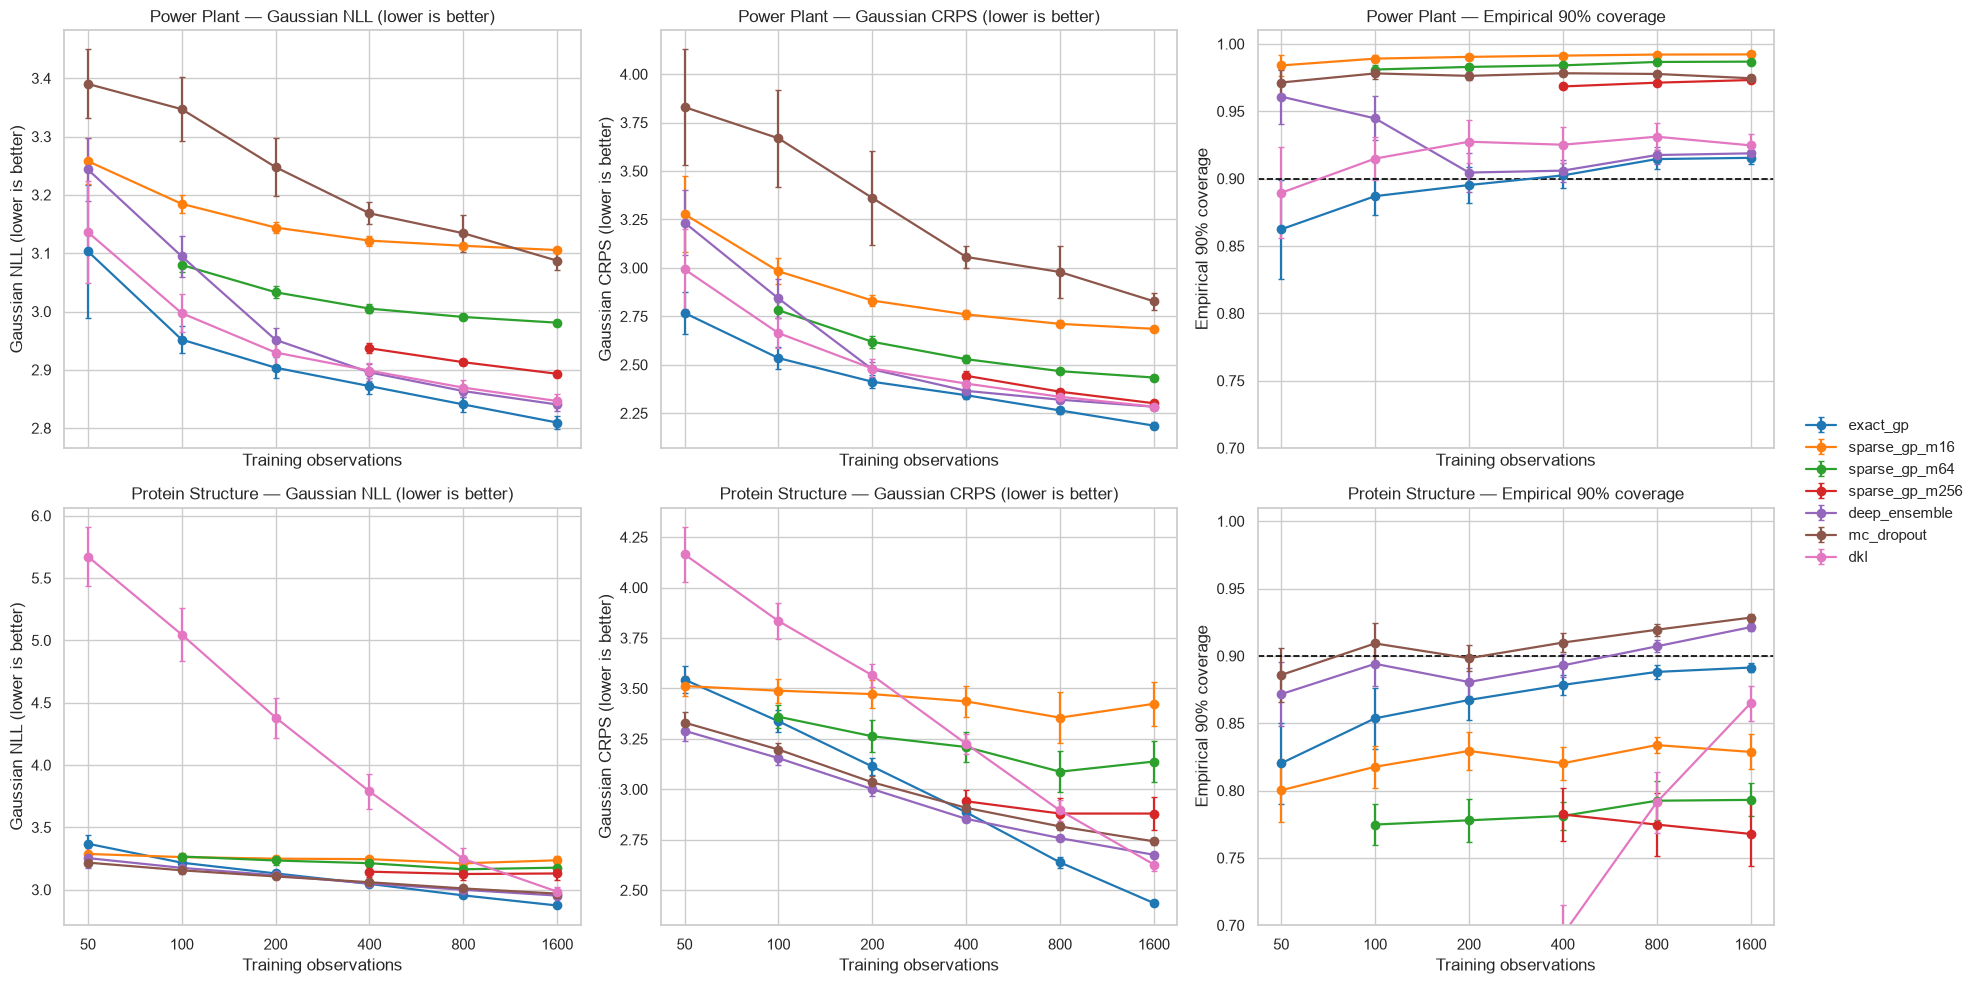

In [5]:
uncertainty_labels = {
    "nll": "Gaussian NLL (lower is better)",
    "crps": "Gaussian CRPS (lower is better)",
    "coverage_90": "Empirical 90% coverage",
}
fig, axes = plt.subplots(len(datasets), len(uncertainty_labels), figsize=(18, 10), sharex=True)
for row, dataset in enumerate(datasets):
    for col, (metric, label) in enumerate(uncertainty_labels.items()):
        ax = axes[row, col]
        metric_data = aggregated[(aggregated["dataset"] == dataset) & (aggregated["metric"] == metric)]
        for model in model_order:
            group = metric_data[metric_data["model"] == model].sort_values("train_size")
            if not group.empty:
                ax.errorbar(group["train_size"], group["mean"], yerr=group["ci95"],
                            marker="o", capsize=2, linewidth=1.6, color=palette[model], label=model)
        if metric == "coverage_90":
            ax.axhline(0.90, color="black", linestyle="--", linewidth=1.2)
            ax.set_ylim(0.7, 1.01)
        ax.set_xscale("log", base=2)
        ax.set_xticks(sorted(results["train_size"].unique()))
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        ax.set_title(f"{dataset_labels[dataset]} — {label}")
        ax.set_xlabel("Training observations")
        ax.set_ylabel(label)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.tight_layout()
plt.show()

In [6]:
uncertainty_winners = []
for (dataset, train_size), current in means.groupby(["dataset", "train_size"]):
    nll_winner = current.loc[current["nll"].idxmin()]
    crps_winner = current.loc[current["crps"].idxmin()]
    coverage_winner = current.loc[current["coverage_error_90"].idxmin()]
    uncertainty_winners.append({
        "dataset": dataset_labels[dataset], "train_size": train_size,
        "best_nll_model": nll_winner["model"], "nll": nll_winner["nll"],
        "best_crps_model": crps_winner["model"], "crps": crps_winner["crps"],
        "closest_coverage_model": coverage_winner["model"],
        "coverage": coverage_winner["coverage_90"],
    })
display(pd.DataFrame(uncertainty_winners))

# Exact GP versus the strongest NN for each proper uncertainty score.
uncertainty_family_rows = []
for (dataset, train_size), current in means.groupby(["dataset", "train_size"]):
    indexed = current.set_index("model")
    for metric in ["nll", "crps"]:
        best_nn = current[current["model"].isin(nn_models)].sort_values(metric).iloc[0]
        uncertainty_family_rows.append({
            "dataset": dataset_labels[dataset], "train_size": train_size,
            "metric": metric, "exact_gp": indexed.loc["exact_gp", metric],
            "best_nn": best_nn["model"], "best_nn_score": best_nn[metric],
            "nn_minus_exact": best_nn[metric] - indexed.loc["exact_gp", metric],
            "dkl": indexed.loc["dkl", metric],
        })
display(pd.DataFrame(uncertainty_family_rows))

for dataset in datasets:
    current = results[(results["dataset"] == dataset) & (results["train_size"] == largest_size)]
    table = current.groupby("model")[["nll", "crps", "coverage_90"]].agg(["mean", "std"])
    print(f"{dataset_labels[dataset]} uncertainty measures at n={largest_size:,}")
    display(table.sort_values(("nll", "mean")))

,dataset,train_size,best_nll_model,nll,best_crps_model,crps,closest_coverage_model,coverage
0,Power Plant,50,exact_gp,3.1032,exact_gp,2.7676,dkl,0.8895
1,Power Plant,100,exact_gp,2.9518,exact_gp,2.5346,exact_gp,0.8870
2,Power Plant,200,exact_gp,2.9036,exact_gp,2.4125,exact_gp,0.8952
3,Power Plant,400,exact_gp,2.8721,exact_gp,2.3429,deep_ensemble,0.9059
4,Power Plant,800,exact_gp,2.8406,exact_gp,2.2643,exact_gp,0.9145
5,Power Plant,1600,exact_gp,2.8095,exact_gp,2.1858,exact_gp,0.9154
6,Protein Structure,50,mc_dropout,3.2172,deep_ensemble,3.2902,mc_dropout,0.8858
7,Protein Structure,100,mc_dropout,3.1553,deep_ensemble,3.1548,deep_ensemble,0.8941
8,Protein Structure,200,mc_dropout,3.1060,deep_ensemble,3.0010,mc_dropout,0.8983
9,Protein Structure,400,exact_gp,3.0463,deep_ensemble,2.8537,mc_dropout,0.9099


,dataset,train_size,metric,exact_gp,best_nn,best_nn_score,nn_minus_exact,dkl
0,Power Plant,50,nll,3.1032,deep_ensemble,3.2435,0.1403,3.1361
1,Power Plant,50,crps,2.7676,deep_ensemble,3.2338,0.4662,2.9928
2,Power Plant,100,nll,2.9518,deep_ensemble,3.0946,0.1428,2.9971
3,Power Plant,100,crps,2.5346,deep_ensemble,2.8425,0.3079,2.6636
4,Power Plant,200,nll,2.9036,deep_ensemble,2.9514,0.0477,2.9297
5,Power Plant,200,crps,2.4125,deep_ensemble,2.4765,0.0640,2.4806
6,Power Plant,400,nll,2.8721,deep_ensemble,2.8957,0.0236,2.8985
7,Power Plant,400,crps,2.3429,deep_ensemble,2.3653,0.0224,2.4030
8,Power Plant,800,nll,2.8406,deep_ensemble,2.8636,0.0230,2.8695
9,Power Plant,800,crps,2.2643,deep_ensemble,2.3197,0.0554,2.3346


Power Plant uncertainty measures at n=1,600


nll            crps         coverage_90        
                  mean     std    mean     std        mean     std
model                                                             
exact_gp        2.8095  0.0237  2.1858  0.0377      0.9154  0.0102
deep_ensemble   2.8405  0.0253  2.2834  0.0366      0.9188  0.0101
dkl             2.8465  0.0273  2.2836  0.0414      0.9247  0.0175
sparse_gp_m256  2.8932  0.0112  2.3014  0.0240      0.9732  0.0036
sparse_gp_m64   2.9808  0.0093  2.4341  0.0238      0.9869  0.0022
mc_dropout      3.0871  0.0330  2.8277  0.0921      0.9745  0.0052
sparse_gp_m16   3.1054  0.0079  2.6855  0.0246      0.9922  0.0022

Protein Structure uncertainty measures at n=1,600


nll            crps         coverage_90        
                  mean     std    mean     std        mean     std
model                                                             
exact_gp        2.8730  0.0136  2.4362  0.0343      0.8913  0.0074
deep_ensemble   2.9527  0.0218  2.6756  0.0324      0.9213  0.0064
mc_dropout      2.9683  0.0162  2.7422  0.0375      0.9284  0.0064
dkl             2.9841  0.0735  2.6272  0.0679      0.8648  0.0281
sparse_gp_m256  3.1298  0.1038  2.8798  0.1790      0.7678  0.0503
sparse_gp_m64   3.1765  0.0768  3.1377  0.2138      0.7931  0.0263
sparse_gp_m16   3.2357  0.0680  3.4238  0.2325      0.8287  0.0278

### Uncertainty findings in relation to the hypothesis

- **Power Plant gives the clearest GP result:** exact GP has the best mean NLL and CRPS at every size, including the smallest. At `n=50`, its advantage over the best NN is **0.140 NLL** and **0.466 CRPS**; both gaps shrink markedly by `n=400`, but never reverse. At `n=1,600`, exact GP also has near-nominal coverage (**0.915**).
- **Protein Structure again rejects a universal GP advantage at very small sizes.** MC dropout has the best NLL through `n=200`, and the deep ensemble has the best CRPS through `n=400`. Exact GP takes the NLL lead at `n=400` and the CRPS lead at `n=800`, then widens both advantages. This matches the RMSE result: the NN methods are strongest early on this dataset, not late.
- **DKL is not a best-of-both-worlds solution here.** Its small-data uncertainty scores are particularly poor on Protein Structure (NLL **5.672** at `n=50`, versus **3.369** for exact GP and **3.217** for MC dropout). Although DKL improves rapidly, it never provides the best NLL, CRPS, or coverage in a stable way.
- **Sparse-GP calibration is dataset-dependent.** At `n=1,600`, sparse GPs are conservative on Power Plant (coverage **0.973–0.992**) but under-cover on Protein Structure (**0.768–0.829**). More inducing points improve Protein Structure RMSE, yet coverage worsens in these runs; approximation quality therefore cannot be judged from RMSE alone.

# 3. Computational time

Final training time covers retraining on the complete subset after epoch selection; validation-based selection and preprocessing are excluded. Inference time covers the complete held-out test set: 1,914 Power Plant observations and 9,146 Protein Structure observations. Both axes use logarithmic scales.

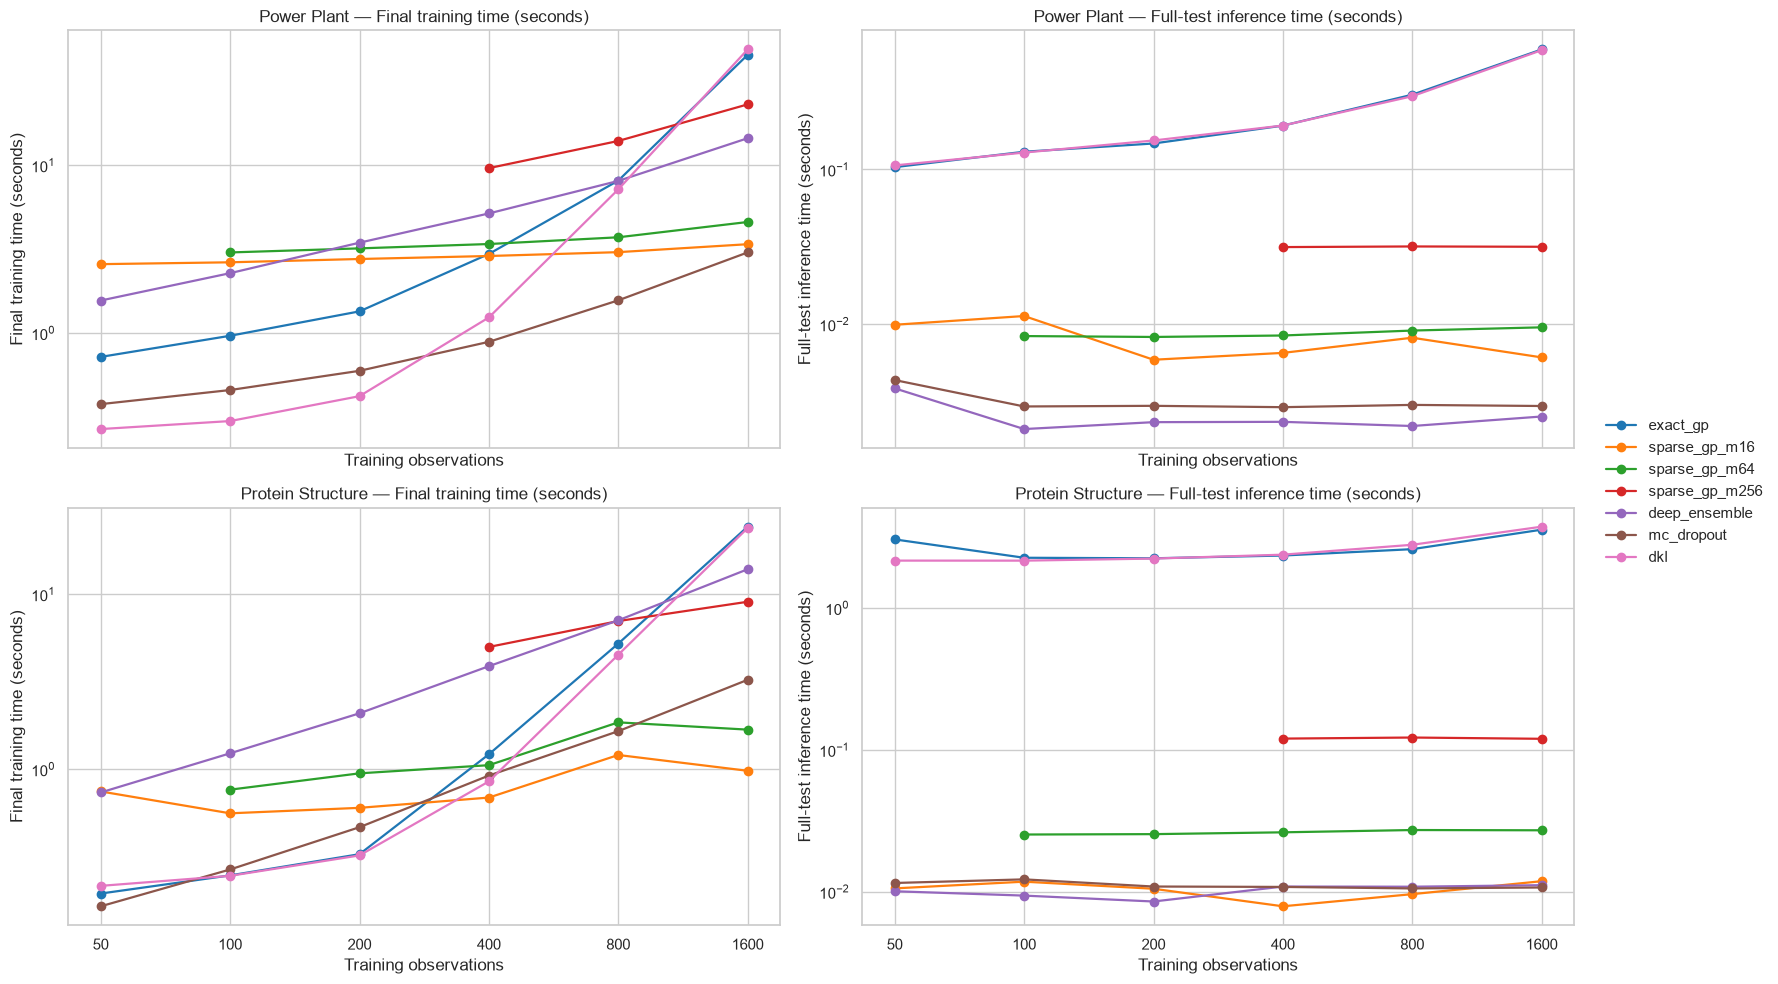

In [7]:
timing_labels = {
    "final_training_time_seconds": "Final training time (seconds)",
    "inference_time_seconds": "Full-test inference time (seconds)",
}
fig, axes = plt.subplots(len(datasets), len(timing_labels), figsize=(16, 10), sharex=True)
for row, dataset in enumerate(datasets):
    for col, (metric, label) in enumerate(timing_labels.items()):
        ax = axes[row, col]
        metric_data = aggregated[(aggregated["dataset"] == dataset) & (aggregated["metric"] == metric)]
        for model in model_order:
            group = metric_data[metric_data["model"] == model].sort_values("train_size")
            if not group.empty:
                ax.plot(group["train_size"], group["mean"], marker="o",
                        linewidth=1.6, color=palette[model], label=model)
        ax.set_xscale("log", base=2)
        ax.set_yscale("log")
        ax.set_xticks(sorted(results["train_size"].unique()))
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        ax.set_title(f"{dataset_labels[dataset]} — {label}")
        ax.set_xlabel("Training observations")
        ax.set_ylabel(label)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.tight_layout()
plt.show()

In [8]:
timing_at_largest = (
    results[results["train_size"] == largest_size]
    .groupby(["dataset", "model"])[["final_training_time_seconds", "inference_time_seconds"]]
    .agg(["mean", "std"])
)
timing_at_largest.index = pd.MultiIndex.from_tuples(
    [(dataset_labels[dataset], model) for dataset, model in timing_at_largest.index],
    names=["dataset", "model"],
)
display(timing_at_largest)

# At every size, select the eligible sparse configuration with the best RMSE and
# quantify its accuracy cost and empirical speed relative to exact GP.
sparse_tradeoff_rows = []
for (dataset, train_size), current in means.groupby(["dataset", "train_size"]):
    indexed = current.set_index("model")
    exact = indexed.loc["exact_gp"]
    best_sparse = current[current["model"].isin(sparse_models)].sort_values("rmse").iloc[0]
    sparse_tradeoff_rows.append({
        "dataset": dataset_labels[dataset], "train_size": train_size,
        "best_sparse": best_sparse["model"],
        "sparse_rmse_gap_pct": 100 * (best_sparse["rmse"] / exact["rmse"] - 1),
        "exact_over_sparse_training_time": (
            exact["final_training_time_seconds"] / best_sparse["final_training_time_seconds"]
        ),
        "exact_over_sparse_inference_time": (
            exact["inference_time_seconds"] / best_sparse["inference_time_seconds"]
        ),
    })
sparse_tradeoff = pd.DataFrame(sparse_tradeoff_rows)
display(sparse_tradeoff)

final_training_time_seconds           \
                                                        mean      std   
dataset           model                                                 
Power Plant       deep_ensemble                      14.4852   0.8745   
                  dkl                                48.9842  19.8567   
                  exact_gp                           45.4953  39.0315   
                  mc_dropout                          3.0225   0.3021   
                  sparse_gp_m16                       3.3834   0.0466   
                  sparse_gp_m256                     23.0495   0.4922   
                  sparse_gp_m64                       4.5885   0.0730   
Protein Structure deep_ensemble                      13.8798   0.7568   
                  dkl                                23.8708   2.6320   
                  exact_gp                           24.2979   3.2103   
                  mc_dropout                          3.2417   0.5013   
                  sparse_gp_m16                       0.9795   1.0424   
                  sparse_gp_m256                      9.0496   8.7317   
                  sparse_gp_m64                       1.6833   1.7663   

                                 inference_time_seconds          
                                                   mean     std  
dataset           model                                          
Power Plant       deep_ensemble                  0.0025  0.0005  
                  dkl                            0.5892  0.0141  
                  exact_gp                       0.5955  0.0166  
                  mc_dropout                     0.0030  0.0004  
                  sparse_gp_m16                  0.0061  0.0006  
                  sparse_gp_m256                 0.0316  0.0013  
                  sparse_gp_m64                  0.0095  0.0008  
Protein Structure deep_ensemble                  0.0111  0.0023  
                  dkl                            3.7409  0.7204  
                  exact_gp                       3.5630  0.5189  
                  mc_dropout                     0.0107  0.0013  
                  sparse_gp_m16                  0.0119  0.0009  
                  sparse_gp_m256                 0.1196  0.0022  
                  sparse_gp_m64                  0.0271  0.0008

,dataset,train_size,best_sparse,sparse_rmse_gap_pct,exact_over_sparse_training_time,exact_over_sparse_inference_time
0,Power Plant,50,sparse_gp_m16,12.8116,0.2801,10.4243
1,Power Plant,100,sparse_gp_m64,6.0340,0.3187,15.5096
2,Power Plant,200,sparse_gp_m64,3.7527,0.4213,17.7691
3,Power Plant,400,sparse_gp_m256,2.0435,0.3080,6.0884
4,Power Plant,800,sparse_gp_m256,1.2622,0.5804,9.5537
5,Power Plant,1600,sparse_gp_m256,1.6725,1.9738,18.8165
6,Protein Structure,50,sparse_gp_m16,-3.7868,0.2611,288.2420
7,Protein Structure,100,sparse_gp_m64,-3.2407,0.3238,89.2833
8,Protein Structure,200,sparse_gp_m64,-0.0974,0.3452,87.9558
9,Protein Structure,400,sparse_gp_m256,-0.9777,0.2437,19.5134


### Time findings and the sparse-GP trade-off

- **The expected sparse-GP training advantage appears only once the dataset is large enough.** At `n=50–800`, the best eligible sparse configuration is actually slower to train than exact GP in these runs (the exact/sparse time ratio is below 1), reflecting variational-optimization overhead. At `n=1,600`, the ordering reverses: exact GP is about **2.0×** slower than `m=256` on Power Plant and **2.7×** slower on Protein Structure.
- **Sparse inference is consistently much cheaper.** At `n=1,600`, exact GP inference is **18.8×** slower than `m=256` on Power Plant and **29.8×** slower on Protein Structure. The advantage is especially relevant for repeated prediction on the 9,146-row Protein test set.
- **The speed–quality exchange depends on the dataset.** At `n=1,600`, `m=256` reduces Power Plant training and inference time for only a **1.7% RMSE penalty**, a favorable approximation. On Protein Structure, it yields similar speed gains but a **9.9% RMSE penalty** plus substantial undercoverage, making the trade-off much less attractive.
- **NN inference is cheapest overall.** MC dropout and the deep ensemble predict quickly; however, training five independent ensemble members is materially more expensive than training the single MC-dropout network.

Runtime results are specific to this hardware, software stack, stopping behavior, and implementation. They should be interpreted as empirical costs rather than hardware-independent complexity estimates.

# Overall answer to the research question

1. **There is no universal small-data ranking.** Power Plant strongly supports the classical expectation that an exact GP is the safer small-data choice. Protein Structure does not: deep ensembles and MC dropout are already better at `n=50–200` on both RMSE and uncertainty scores. Dataset structure and inductive bias matter at least as much as sample count.
2. **The NN methods improve as data grows, but relative performance does not improve monotonically.** Their absolute RMSE falls on both tasks. Yet exact GP improves at least as quickly: it remains dominant on Power Plant and overtakes the NNs on Protein Structure around `n=400–800`. The anticipated GP-to-NN crossover is therefore **not observed up to `n=1,600`**; Protein Structure shows the reverse crossover.
3. **DKL does not combine the strengths reliably in this setup.** It improves substantially with more observations, especially on Protein Structure, but never becomes the leading method. Its learned feature map appears data-hungry without delivering a later advantage within the tested range.
4. **Sparse GPs deliver their intended computational benefit mainly at the largest size.** Their inference advantage is clear throughout, while their training advantage emerges at `n=1,600`. The performance cost is modest on Power Plant and large on Protein Structure, so sparse approximation should be evaluated per dataset and with calibration metrics—not assumed to be a uniformly favorable replacement.

These conclusions apply to the tested range, architectures, optimization settings, and kernels. A claim that NNs eventually dominate would require larger training sizes and comparable hyperparameter tuning beyond `n=1,600`.